
<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #990099;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> (Analysis) and (Validation)

        

In [2]:
# Import necessary libraries
import sys
sys.path.append('../..') 
from config import MODEL_SAVE_BEST, MODEL_SAVE_LAST#,BASE_DIR
import numpy as np
import matplotlib.pyplot as plt
from reid.similarity import similarity_scores
from reid import model, data, similarity
from config import dataset_path
from reid.data import prepare_datasets
from reid.model import create_model 
import seaborn as sns 



<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #11456c;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> Test scores Plot (Same) & (Diffrent) before Training

        

In [3]:
# Prepare the datasets
train_ds, val_ds = prepare_datasets(dataset_path)
# Create an instance of the model
model_instance = create_model()

# Instance to calculate similarity scores
same_scores, diff_scores = similarity_scores(model_instance, val_ds)

# Display the elements of each array
print("Similarity scores for same pairs :", same_scores[:5])
print("Similarity scores for different :", diff_scores[:5])


Similarity scores for same pairs : [0.9983846  0.99893963 0.9987669  0.99901825 0.9991564 ]
Similarity scores for different : [0.9975825  0.9971956  0.9979641  0.99764884 0.9976064 ]


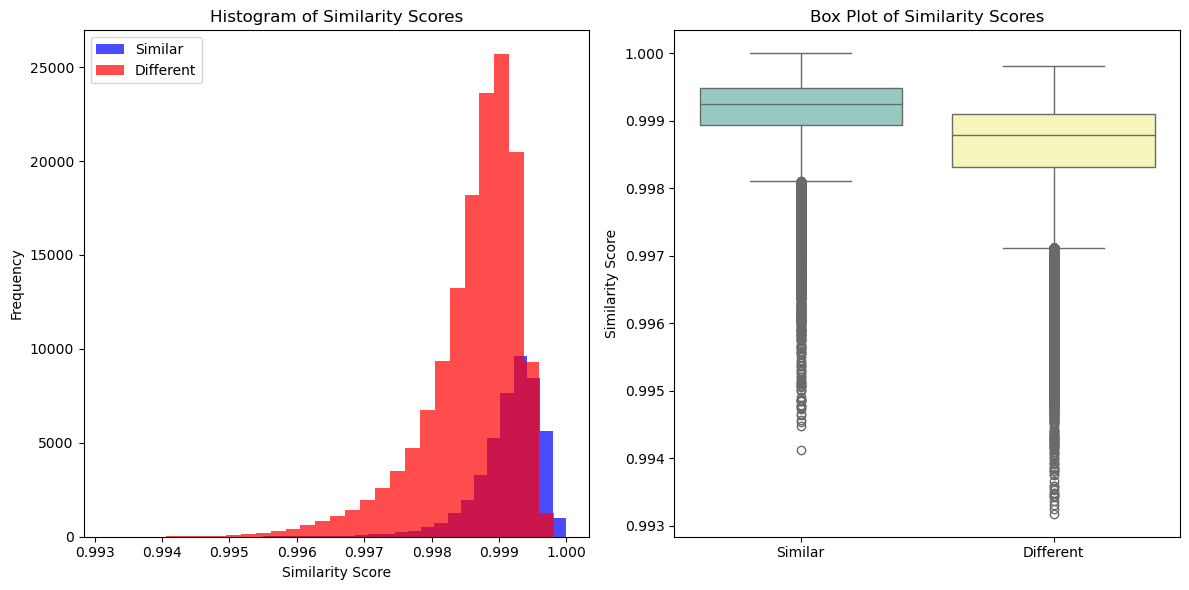

In [4]:
# Visualization
plt.figure(figsize=(12, 6))

# Histogram
plt.subplot(1, 2, 1)
plt.hist(same_scores, bins=30, alpha=0.7, color='blue', label='Similar') 
plt.hist(diff_scores, bins=30, alpha=0.7, color='red', label='Different') 
plt.title('Histogram of Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.legend()

# Box Plot
plt.subplot(1, 2, 2)
sns.boxplot(data=[same_scores, diff_scores], palette="Set3")
plt.xticks([0, 1], ['Similar', 'Different'])
plt.title('Box Plot of Similarity Scores')
plt.ylabel('Similarity Score')

plt.tight_layout()
plt.show()



<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #11456c;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> Load weights Models after Training

        

In [1]:
import matplotlib.pyplot as plt
model.load_weights(MODEL_SAVE_BEST)
same_scores, diff_scores = similarity_scores(model, val_ds)
# Visualization
plt.figure(figsize=(12, 6))

# Histogram
plt.subplot(1, 2, 1)
plt.hist(same_scores, bins=30, alpha=0.7, color='blue', label='Similar') 
plt.hist(diff_scores, bins=30, alpha=0.7, color='red', label='Different') 
plt.title('Histogram of Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.legend()

# Box Plot
plt.subplot(1, 2, 2)
sns.boxplot(data=[same_scores, diff_scores], palette="Set3")
plt.xticks([0, 1], ['Similar', 'Different'])
plt.title('Box Plot of Similarity Scores')
plt.ylabel('Similarity Score')

plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'reid'

## Hard (SAME) Visualization
Identify challenging data points for analysis or further training purposes.

In [ ]:
model.load_weights(MODEL_SAVE_BEST)
#model.load_weights('last_model copy.keras')

for images, labels in val_ds:
    similarity = model(images).numpy()
    # Create a mask for pairs labeled as similar (1) but with high similarity scores (> 0.75)
    hard_diff_mask = (labels == 0) & (similarity > 0.75)
    if hard_diff_mask.any():
    # Find indices of hard positive pairs and stack them into a 2D array
        pairs = np.stack(np.where(hard_diff_mask), axis=-1)
        break

In [ ]:
for images, labels in val_ds:
    similarity = model(images).numpy()
    # Create a mask for pairs labeled as similar (1) but with low similarity scores (< 0.3)
    hard_same_mask = (labels == 1) & (similarity < 0.3)
    if hard_same_mask.any():
    # Find indices of hard positive pairs and stack them into a 2D array
        pairs = np.stack(np.where(hard_same_mask), axis=-1)
        break

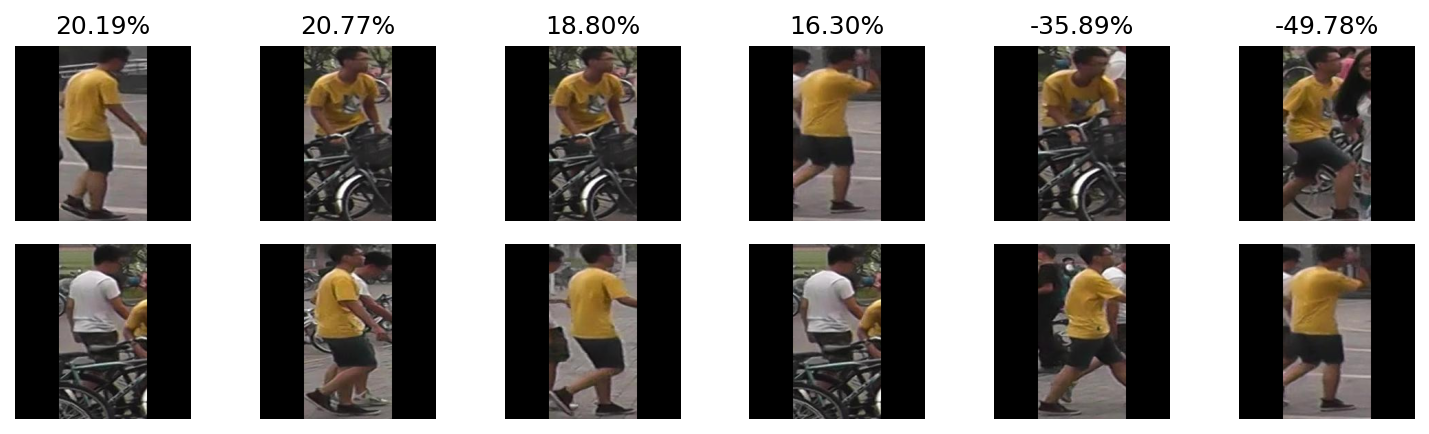

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, min(len(pairs), 6), figsize=(10, 3), dpi=150)
for ax, pair in zip(axes.T, pairs[np.random.permutation(len(pairs))]):
    pair = tuple(pair)
    ax[0].imshow(Image.fromarray(images[pair[0]].astype('uint8')))
    ax[1].imshow(Image.fromarray(images[pair[1]].astype('uint8')))
    ax[0].set_title(f"{similarity[pair]:.2%}")
    ax[0].axis('off')
    ax[1].axis('off')
fig.tight_layout()
plt.show(fig)

## Hard (Diffrent) Visualization

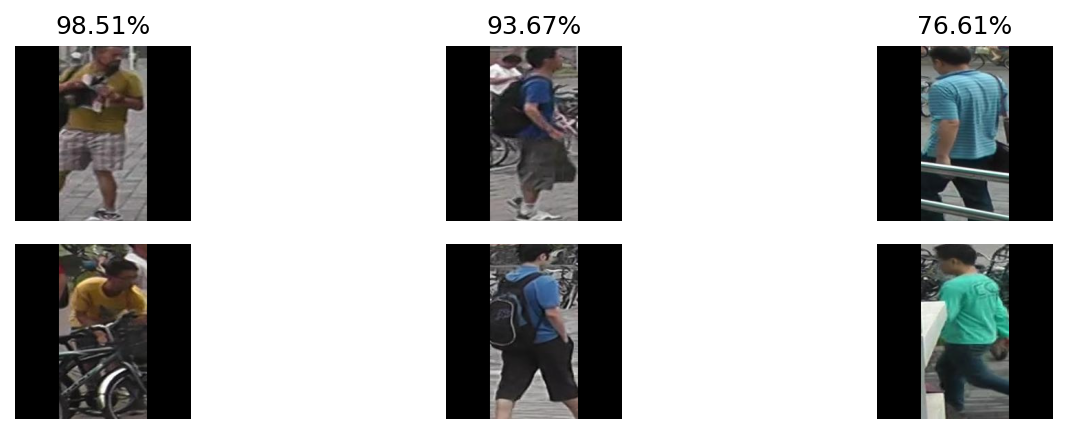

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, min(len(pairs), 6), figsize=(10, 3), dpi=150)
for ax, pair in zip(axes.T, pairs[np.random.permutation(len(pairs))]):
    pair = tuple(pair)
    ax[0].imshow(Image.fromarray(images[pair[0]].astype('uint8')))
    ax[1].imshow(Image.fromarray(images[pair[1]].astype('uint8')))
    ax[0].set_title(f"{similarity[pair]:.2%}")
    ax[0].axis('off')
    ax[1].axis('off')
fig.tight_layout()
plt.show(fig)